# Русский биомедицинский поиск: RusBEIR + Qwen

Полный официальный rus-NFCorpus: 3633 документа, 323 test queries. Текст запроса и документа - основной вход.

Быстрая проверка ниже воспроизводит **опубликованные численные результаты**, а не заново обучает модели. Полный прогон включается отдельно и занимает часы. [Отчёт и код](https://github.com/NikiBagramov/russian-biomedical-retrieval).

In [1]:
from pathlib import Path
import os, subprocess, sys, json
SLUG = 'russian-biomedical-retrieval'
ROOT = Path.cwd()
if not (ROOT / "project.json").exists() or json.loads((ROOT / "project.json").read_text(encoding="utf-8"))["slug"] != SLUG:
    target = ROOT / SLUG
    if not target.exists():
        subprocess.run(["git", "clone", 'https://github.com/NikiBagramov/russian-biomedical-retrieval', str(target)], check=True)
    ROOT = target
os.chdir(ROOT)
assert json.loads((ROOT / "project.json").read_text(encoding="utf-8"))["slug"] == SLUG
print(ROOT.name)


russian-biomedical-retrieval


In [2]:
INSTALL = False  # Set True in a fresh Colab / Kaggle environment
if INSTALL:
    subprocess.run([sys.executable, "-m", "pip", "install", "-r", "requirements.txt"], check=True)

In [3]:
subprocess.run([sys.executable, "scripts/verify_results.py"], check=True)

CompletedProcess(args=['C:\\Users\\nbagr\\AppData\\Local\\Programs\\Python\\Python310\\python.exe', 'scripts/verify_results.py'], returncode=0)

In [4]:
import pandas as pd
display(pd.read_csv("artifacts/results.csv"))

,method,P_10,recall_10,recall_100,ndcg_cut_10,map_cut_10,mrr_10
0,bm25,0.215789,0.154147,0.242953,0.303818,0.117720,0.491296
1,bm25_bge_reranker512,0.229412,0.157869,0.242953,0.328244,0.126413,0.541126
2,bm25_raw,0.163158,0.108432,0.175207,0.236117,0.084397,0.428426
3,bm25_twofield,0.213313,0.150150,0.244583,0.303426,0.117804,0.500162
4,e5_large,0.225077,0.151390,0.280869,0.305711,0.110885,0.499520
5,e5_large_bge_reranker512,0.235913,0.156124,0.280869,0.330953,0.126559,0.537364
6,e5_small,0.196904,0.126927,0.247159,0.267211,0.092758,0.449224
7,qwen_embedding,0.217028,0.145404,0.271306,0.295965,0.104464,0.492562
8,rrf,0.239628,0.167499,0.284613,0.329721,0.123997,0.528515
9,rrf_bge_reranker512,0.246130,0.168302,0.284613,0.344427,0.132404,0.561461


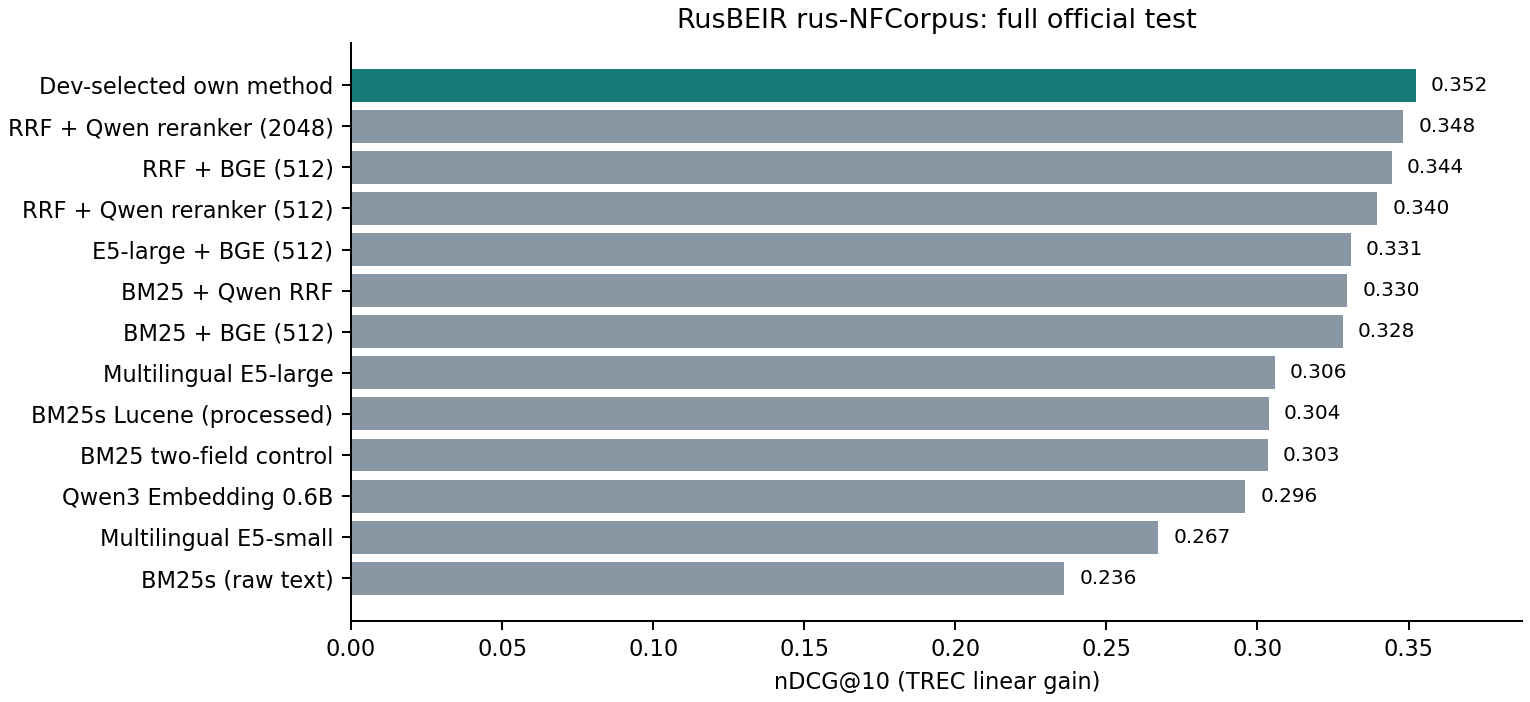

In [5]:
from IPython.display import display, Image
display(Image(filename="artifacts/figures/main.png"))

## Полное новое воспроизведение

Требует BF16 GPU и скачивания открытых моделей. Создаёт отдельный `runs/reproduce_*`; результаты исходного запуска не меняются. T4/FP16 не проверялись.

In [6]:
RUN_FULL = False
if RUN_FULL:
    subprocess.run([sys.executable, "scripts/run_pipeline.py", "--reproduce", "--download", "--report"], check=True)

## Ограничения

CPU BM25s отличается от Elasticsearch статьи. BGE 512-token cap взят из pinned source; статья указывает другую длину. Финальная композиция выбирает веса на dev и не является строго zero-shot. Глобальное SotA не доказано.